In [1]:
print('hola')

hola


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
import os
ruta = '../data/raw/accidentes.xlsx'
print(f"Tamaño: {os.path.getsize(ruta)} bytes")

Tamaño: 15924139 bytes


In [10]:
import os

ruta = '../data/raw/accidentes.csv'

print(f"Existe: {os.path.exists(ruta)}")
print(f"Tamaño: {os.path.getsize(ruta)} bytes")

with open(ruta, 'rb') as f:
    firma = f.read(8)
    print(f"Primeros bytes (hex): {firma.hex()}")
    print(f"Primeros bytes (texto): {firma}")

Existe: True
Tamaño: 46524398 bytes
Primeros bytes (hex): 434f424552545552
Primeros bytes (texto): b'COBERTUR'


In [13]:
df = pd.read_csv(ruta, encoding='utf-8-sig')
df.head()

,COBERTURA,ID_ENTIDAD,ID_MUNICIPIO,ANIO,MES,ID_HORA,ID_MINUTO,ID_DIA,DIASEMANA,URBANA,...,PEATMUERTO,PEATHERIDO,CICLMUERTO,CICLHERIDO,OTROMUERTO,OTROHERIDO,NEMUERTO,NEHERIDO,CLASACC,ESTATUS
0,Municipal,1,1,2015,Enero,20,40,27,Martes,Accidente en no intersección,...,0,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas
1,Municipal,1,1,2015,Enero,0,0,1,Jueves,Accidente en no intersección,...,0,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas
2,Municipal,1,1,2015,Enero,17,0,28,Miércoles,Accidente en intersección,...,0,0,0,0,0,0,0,0,No fatal,Cifras definitivas
3,Municipal,1,1,2015,Enero,8,40,1,Jueves,Accidente en no intersección,...,0,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas
4,Municipal,1,1,2015,Enero,23,40,30,Viernes,Accidente en intersección,...,0,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas


In [14]:
df.shape

(180066, 45)

In [15]:
df.columns

Index(['COBERTURA', 'ID_ENTIDAD', 'ID_MUNICIPIO', 'ANIO', 'MES', 'ID_HORA',
       'ID_MINUTO', 'ID_DIA', 'DIASEMANA', 'URBANA', 'SUBURBANA', 'TIPACCID',
       'AUTOMOVIL', 'CAMPASAJ', 'MICROBUS', 'PASCAMION', 'OMNIBUS', 'TRANVIA',
       'CAMIONETA', 'CAMION', 'TRACTOR', 'FERROCARRI', 'MOTOCICLET',
       'BICICLETA', 'OTROVEHIC', 'CAUSAACCI', 'CAPAROD', 'SEXO', 'ALIENTO',
       'CINTURON', 'ID_EDAD', 'CONDMUERTO', 'CONDHERIDO', 'PASAMUERTO',
       'PASAHERIDO', 'PEATMUERTO', 'PEATHERIDO', 'CICLMUERTO', 'CICLHERIDO',
       'OTROMUERTO', 'OTROHERIDO', 'NEMUERTO', 'NEHERIDO', 'CLASACC',
       'ESTATUS'],
      dtype='str')

In [ ]:
df_alcoholizados = df[df['']]

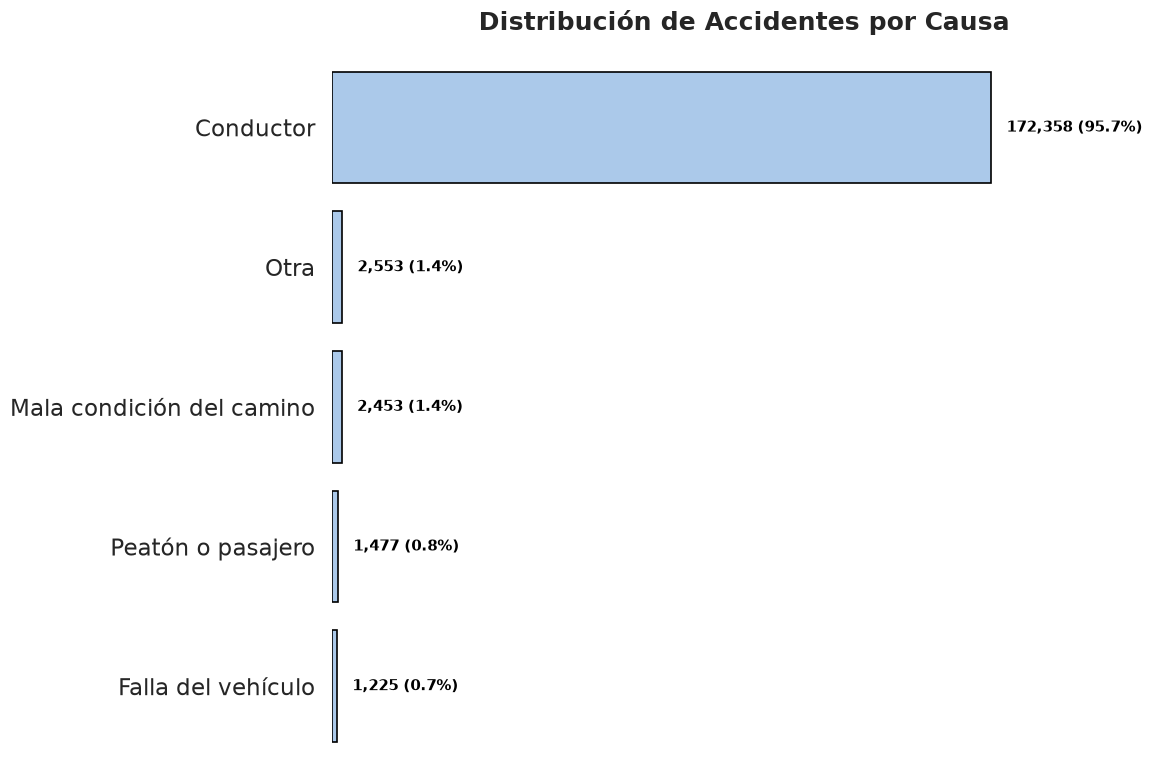

In [19]:


# 1. Aplicar el estilo de Seaborn
sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("pastel")

# 2. Calcular los conteos y porcentajes
conteo_causas = df['CAUSAACCI'].value_counts(dropna=False)
total_causas = conteo_causas.sum()
porcentajes = (conteo_causas / total_causas * 100).round(1)

# 3. Crear la figura (más alta para que quepan todas las causas)
fig, ax = plt.subplots(figsize=(12, 8))

# 4. Dibujar el gráfico de barras HORIZONTAL
sns.barplot(
    x=conteo_causas.values, 
    y=conteo_causas.index, 
    ax=ax,
    edgecolor='black',
    linewidth=1.2
)

# 5. Añadir las etiquetas (conteo exacto y porcentaje)
for i, (valor, pct) in enumerate(zip(conteo_causas.values, porcentajes.values)):
    # En gráfico horizontal, el texto va a la derecha de la barra (valor + un margen)
    margen = total_causas * 0.015
    ax.text(
        valor + margen, i, 
        f' {valor:,} ({pct}%)', 
        ha='left', va='center', 
        fontweight='bold', fontsize=11, color='black'
    )

# 6. Ajustes estéticos finales
ax.set_title('Distribución de Accidentes por Causa', fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('') 
ax.set_ylabel('') 

# --- MODIFICACIÓN: Eliminar los valores del eje X (por ser barras horizontales) ---
ax.set_xticks([]) 

# Ajustar el límite del eje X para que las etiquetas no se corten
ax.set_xlim(0, conteo_causas.max() * 1.25)

# Quitar la cuadrícula en ambos ejes para un look más limpio
ax.grid(False) 

# Quitar los bordes (incluyendo el inferior, que es donde estaban los valores)
sns.despine(left=True, top=True, right=True, bottom=True)

plt.tight_layout()
plt.show()

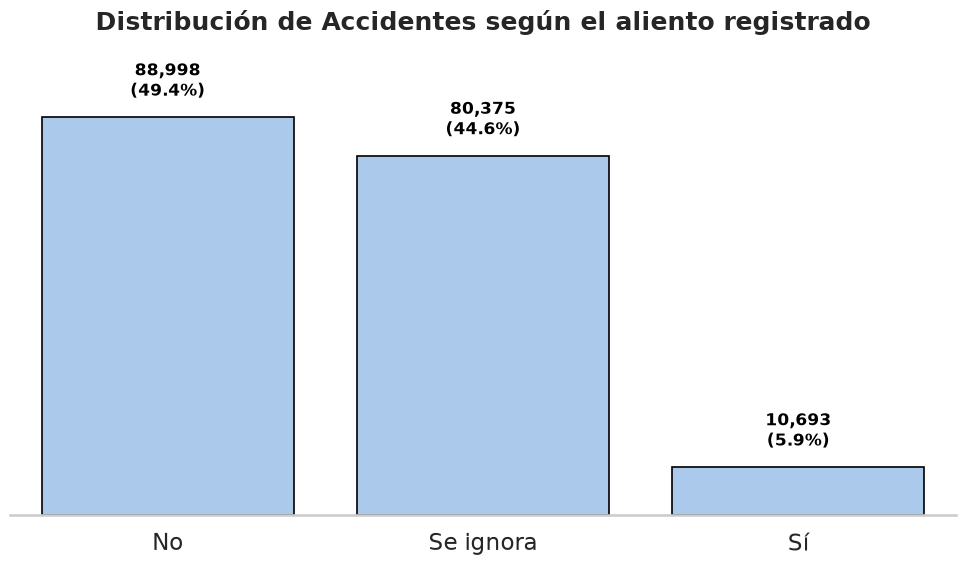

In [18]:
# 1. Aplicar el estilo de Seaborn
sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("pastel")

# 2. Calcular los conteos y porcentajes
# (Usamos dropna=False por si hay valores nulos, para que no desaparezcan)
conteo_aliento = df['ALIENTO'].value_counts(dropna=False)
total = conteo_aliento.sum()
porcentajes = (conteo_aliento / total * 100).round(1)

# 3. Crear la figura
fig, ax = plt.subplots(figsize=(10, 6))

# 4. Dibujar el gráfico de barras
sns.barplot(
    x=conteo_aliento.index, 
    y=conteo_aliento.values, 
    ax=ax,
    edgecolor='black', # Borde negro para que resalten
    linewidth=1.2
)

# 5. Añadir las etiquetas con el conteo exacto y el porcentaje
for i, (valor, pct) in enumerate(zip(conteo_aliento.values, porcentajes.values)):
    # Posicionamos el texto un poco arriba de la barra (valor + 2% del total para dar aire)
    ax.text(
        i, valor + (total * 0.02), 
        f'{valor:,}\n({pct}%)', 
        ha='center', va='bottom', 
        fontweight='bold', fontsize=12, color='black'
    )

# 6. Ajustes estéticos finales
ax.set_title('Distribución de Accidentes según el aliento registrado', fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('') # Quitamos el título del eje X porque las categorías son obvias
ax.set_ylabel('')
ax.set_yticks([]) 

# Ajustar el límite del eje Y para que las etiquetas no se corten
ax.set_ylim(0, total * 0.15 if total * 0.15 > conteo_aliento.max() else conteo_aliento.max() * 1.15)

# Quitar las líneas de la cuadrícula en el eje X para que se vea más limpio
ax.grid(axis='x', visible=False)

# Quitar los bordes superior e izquierdo (opcional, se ve más moderno)
sns.despine(left=True, top=True)

plt.tight_layout()
plt.show()